# 09 - Could generation artifacts explain the decline?

*This notebook was added for the rebuttal.*

Our composites are made by cutting objects out of one photo and pasting them onto an inpainted background. This leaves traces: where and how large the object is placed, how clean its mask is, how well the background was inpainted, and how visible the seam around the object is. This raises the question of whether such artifacts, rather than semantics, produce the decline.

By design they should not, since position and scale are drawn without looking at the rank, and every background is combined with objects from the whole rank axis. But artifacts could still change with rank indirectly, for example if the object classes that sit at high ranks happen to have smaller or messier cutouts.

To test this, we:

1. Check whether the generation properties change along the semantic axis, and how much of the decline they could explain.
2. Compare only composites that share the same inpainted background and the same object cutout.
3. Measure the seams around the pasted objects.

In [2]:
import json
from pathlib import Path

# Repository paths
REPO_ROOT = Path.cwd()
OUTPUT_DIR = REPO_ROOT / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CLASS_INDEX = REPO_ROOT / "helper_files" / "imagenet_class_index.json"

# Prediction CSVs from notebook 03
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"

# ImageNet-OOC1k dataset: provided images and metadata in source/, everything we generate in generated/
DATASET_DIR = REPO_ROOT / "ImageNet-OOC1k"
SOURCE_DIR = DATASET_DIR / "source"
GENERATED_DIR = DATASET_DIR / "generated"
COMPOSITES_DIR = GENERATED_DIR / "composites"

# The reconstructed generation properties of every composite are saved here
VARIABLES_PATH = OUTPUT_DIR / "generation_variables.csv"

# All evaluated models with composite predictions (all 35 if you ran notebook 03 with ALL_MODELS)
ALL_MODELS = sorted({path.name.split("_composite_ooc_")[0] for path in PREDICTIONS_DIR.glob("*_composite_ooc_*.csv")})

N_OBJECTS = 3000            # object cutouts sampled for the boundary measurements
N_PER_OBJECT = 10           # composites sampled per cutout
NUM_WORKERS = 16

BIN_WIDTH = 25              # ranks per bin, as in notebook 05
SEED = 42

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# Analysis and plotting functions live outside the notebook to keep it readable.
from ooc1k.analysis.generation_artifacts import (
    COVARIATES,
    fit_binned_curve,
    fit_rank_slopes,
    get_background_sizes,
    get_boundary_measures,
    get_cutout_geometry,
    get_generation_variables,
    get_object_only_accuracy,
    get_variable_drift,
    sample_composites,
)
from ooc1k.analysis.semantic_distance import load_composite_correctness
from ooc1k.analysis.visual_semantic_axes import get_axis_curves
from ooc1k.plotting.h_generation_artifacts import plot_adjusted_curve

/pfss/mlde/workspaces/mlde_wsp_PI_Roig/bersch/conda/envs/ooc/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Setup

All three questions use the same data: for every composite, whether each model got it right (top-1), the composite metadata with the placement of the object, and the generation settings of notebook 02.

In [4]:
correct = load_composite_correctness(PREDICTIONS_DIR, COMPOSITES_DIR / "metadata.csv", CLASS_INDEX, ALL_MODELS)
metadata = pd.read_csv(COMPOSITES_DIR / "metadata.csv")
config = json.loads((COMPOSITES_DIR / "config.json").read_text())
ranks = metadata["dissimilarity_rank"].values
background_ids, object_names = metadata["background_id"].values, metadata["object_image_name"].values

print(f"{len(correct):,} composites, {len(ALL_MODELS)} models")

953,862 composites, 35 models


## 1. Do generation properties change with semantic rank?

We reconstruct 18 properties of every composite, in three groups:

- **Placement:** the horizontal and vertical position of the object's center, its distance from the image center (eccentricity) and from the nearest border, and whether it was rotated.
- **Scale:** the sampled scale factor, the object's width, height and area relative to the background (bounding box and actual mask), its aspect ratio and how much that ratio was distorted, and whether the minimum size or the cap at half the background was hit.
- **Cutout:** how much of its bounding box the mask fills, and how complex its outline is (perimeter relative to the square root of the area).

Most of these come straight from the metadata or the object masks. The exact scale factor and the rotation are not stored, so we replay them from each composite's seed, exactly as notebook 02 drew them. Replaying the size limits then has to give the recorded object size, which is a nice check that the replay works.

All 18 properties of every composite are saved together in one CSV file (`VARIABLES_PATH`), in case you want to look at them yourself. The masks are read from disk, so this takes a few minutes.

In [5]:
backgrounds = pd.read_csv(SOURCE_DIR / "metadata.csv")
backgrounds = backgrounds[backgrounds["image_id"].isin(metadata["background_id"])]

cutouts = get_cutout_geometry(SOURCE_DIR, metadata["object_image_name"].unique())
background_sizes = get_background_sizes(SOURCE_DIR, backgrounds)
variables = get_generation_variables(metadata, cutouts, background_sizes, config)
pd.concat([metadata[["filename"]], variables], axis=1).to_csv(VARIABLES_PATH, index=False)

print(f"{variables['rotated'].mean():.1%} of the objects were rotated")
print(f"For the other objects, the replayed size matches the metadata in {variables['size_matches'].mean():.2%} of the composites")
print(f"Saved to {VARIABLES_PATH}")

Cutouts:   0%|          | 0/12320 [00:00<?, ?it/s]

Cutouts: 100%|██████████| 12320/12320 [00:47<00:00, 257.31it/s]


29.9% of the objects were rotated
For the other objects, the replayed size matches the metadata in 100.00% of the composites
Saved to /pfss/mlde/workspaces/mlde_wsp_PI_Roig/bersch/repositories/OOC-Dataset-Creator/imagenet-ooc1k/outputs/generation_variables.csv


For every property, we now check two things. First, how much it changes along the semantic axis: its Spearman correlation with rank, and its mean in the first and the last rank bin. Second, how much of the accuracy change between these bins it could explain: its change times its own effect on accuracy (the slope of accuracy, averaged over all models, on the property). This contribution is deliberately generous, since the property also gets credit for everything it happens to correlate with, semantics included.

The contributions of different properties cannot be added up: many scale properties are different views of the same size limits, so a sum would count the same thing several times. What matters is how large the biggest single contribution is, compared with the observed change.

What about inpainting? How well a background was inpainted is the same for all composites on that background, and every background is combined with objects from the whole rank axis (printed below), so inpainting quality cannot change along the axis.

None of the properties changes noticeably along the axis: all correlations with rank are tiny. Even with the generous estimate, no single property could explain more than a few percent of the decline, and several of them would even push accuracy up rather than down.

In [6]:
accuracy = correct.mean(axis=1).values
drift = get_variable_drift(variables, ranks, accuracy, BIN_WIDTH)

ranks_per_background = metadata.groupby("background_id")["dissimilarity_rank"]
print(f"Every one of the {ranks_per_background.ngroups} backgrounds has composites from rank {ranks_per_background.min().max()} or lower up to rank {ranks_per_background.max().min()} or higher")
print(f"Observed accuracy change from the first to the last bin: {drift.attrs['observed_change']:+.2f} pp")
drift.round(3)

Every one of the 260 backgrounds has composites from rank 2 or lower up to rank 998 or higher
Observed accuracy change from the first to the last bin: -14.46 pp


,group,rho with rank,first bin,last bin,contribution (pp),share of change (%)
center_x,placement,-0.000,0.502,0.500,0.001,-0.010
center_y,placement,0.000,0.498,0.497,-0.005,0.031
eccentricity,placement,0.002,0.173,0.174,-0.063,0.438
border_distance,placement,-0.001,0.132,0.132,0.001,-0.010
rotated,placement,-0.001,0.301,0.296,0.009,-0.064
scale_factor,scale,-0.001,0.550,0.550,-0.005,0.034
relative_width,scale,-0.013,0.457,0.448,-0.223,1.545
relative_height,scale,0.006,0.454,0.456,0.144,-0.995
bbox_area,scale,-0.006,0.205,0.202,-0.383,2.649
mask_area,scale,0.012,0.103,0.103,0.108,-0.745


## 2. Do inpainting and cutout quality explain the decline?

The properties above are only the ones we can measure. Inpainting quality and how clean a cutout looks are hard to put into numbers. But we can hold them fixed instead: if we only compare composites that share the **same inpainted background** and the **same object cutout**, neither of them can change with rank.

We do this with a linear regression of correctness (0 or 1) on rank, which gives the slope in percentage points per 100 ranks, and add controls step by step:

1. **Rank only**, without controls.
2. **+ placement and scale**: the covariates in `COVARIATES`.
3. **+ background**: every background gets its own intercept (a "fixed effect"), which removes everything that is constant for a background, including its inpainting quality.
4. **+ object instance**: every object cutout gets its own intercept too, which removes its mask, its edges and its source photo.

The last step is strict. Besides cutout quality, it also removes real differences in how hard objects are to recognise. Some objects are simply harder, and if those happen to sit at higher ranks on average, part of the semantic effect is removed with them. So we also try a fifth variant: instead of an intercept per object, we use each model's own **object-only accuracy** on that cutout (from notebook 03: the same cutout and mask on black, white and pink noise, without any background). This measures how hard the cutout is, artifacts included, but leaves the comparison between objects in. Both variants are sensitivity checks, not lower and upper bounds of the "true" effect.

The 95% confidence intervals account for composites sharing a background or an object (standard errors clustered by both). Fitting all 35 models takes a few minutes.

Placement, scale and background barely change the slope; it even gets slightly steeper. With an intercept for every object instance, about two thirds of the slope remain, and with object-only accuracy instead, almost 90%. In every variant, all models keep a slope that is clearly negative.

In [7]:
object_only = get_object_only_accuracy(PREDICTIONS_DIR, ALL_MODELS, metadata["object_image_name"])

specifications = {
    "rank only": {},
    "+ placement and scale": {"covariates": variables[COVARIATES]},
    "+ background": {"covariates": variables[COVARIATES], "fixed_effects": [background_ids]},
    "+ object instance": {"covariates": variables[COVARIATES], "fixed_effects": [background_ids, object_names]},
    "object-only accuracy instead": {"covariates": variables[COVARIATES], "fixed_effects": [background_ids], "model_covariates": object_only},
}
slopes = {name: fit_rank_slopes(ranks, correct, [background_ids, object_names], **specification) for name, specification in specifications.items()}

# Median slope over models, how much of the slope without controls remains, and how many models stay significantly negative
pd.DataFrame({
    name: {
        "median slope (pp per 100 ranks)": round(result["slope"].median(), 3),
        "median slope retained (%)": round((100 * result["slope"] / slopes["rank only"]["slope"]).median(), 1),
        "models with CI below zero": f"{(result['ci_high'] < 0).sum()}/{len(result)}",
    }
    for name, result in slopes.items()
}).T

,median slope (pp per 100 ranks),median slope retained (%),models with CI below zero
rank only,-0.929,100.0,35/35
+ placement and scale,-0.979,105.5,35/35
+ background,-0.977,104.4,35/35
+ object instance,-0.608,66.5,35/35
object-only accuracy instead,-0.782,87.1,35/35


### The decline after all controls

A single slope forces a straight line, while our claim is about a steady decline. So we also fit the strictest model with one indicator per rank bin instead of the linear rank term. Each bin then gets its own accuracy change relative to the first bin, after removing placement, scale, background and object instance: the same curve as in notebook 05, but only from comparisons within the same background and the same cutout. For comparison, the plot also shows the curve without controls, shifted to start at zero.

Even when we only compare composites with the same background and the same cutout, accuracy still declines by about 10 percentage points across the axis, and almost in every single step.

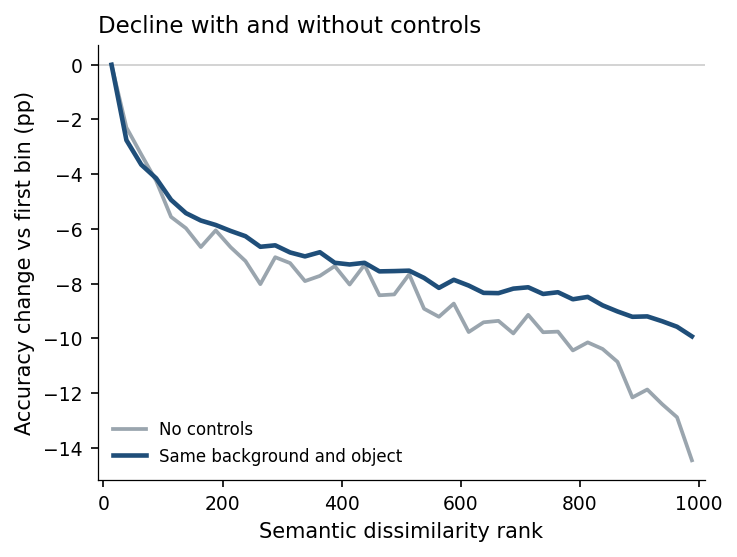

Without controls, accuracy changes by -14.46 pp from the first to the last bin; with all controls by -9.93 pp
Monotonicity of the adjusted curve (Spearman of bin and accuracy change): -0.993


In [8]:
adjusted = fit_binned_curve(ranks, correct, variables[COVARIATES], [background_ids, object_names], BIN_WIDTH).mean(axis=1)
marginal = get_axis_curves(ranks, correct, BIN_WIDTH).mean(axis=1)
marginal = 100 * (marginal - marginal.iloc[0])

fig = plot_adjusted_curve(marginal, adjusted)
fig.savefig(FIG_DIR / "artifact_controls.pdf")
plt.show()

print(f"Without controls, accuracy changes by {marginal.iloc[-1]:+.2f} pp from the first to the last bin; with all controls by {adjusted.iloc[-1]:+.2f} pp")
print(f"Monotonicity of the adjusted curve (Spearman of bin and accuracy change): {spearmanr(np.arange(len(adjusted)), adjusted)[0]:.3f}")

## 3. Do boundary artifacts explain the decline?

One artifact is still left. The same cutout may blend in nicely on one background but leave a visible seam on another. Such a pair-specific seam is not removed by the background and object intercepts above, since it depends on the combination of both. So we measure it directly.

Storing a mask for every composite would have taken a lot of space, so we rebuild a sample of composites from their seeds, exactly as notebook 02 made them. We draw `N_OBJECTS` object cutouts and `N_PER_OBJECT` of their composites each, so that we can still give every object its own intercept. Around each object's edge, we measure three discontinuities between a thin band just inside and a thin band just outside: in **luminance**, in **color** (both in Lab color space), and in the **gradient** (how sharp the edge is).

There is a catch: a semantically distant object really does look more different from its surroundings, so the raw contrast partly is the effect we study. We therefore measure the same bands at the same place on the background alone, without the object, and subtract this. What remains, the **excess** contrast, is what the pasting adds on top of what the background already has there.

Then we fit the strictest model from above on this sample, once as before and once with the three excess measures as additional covariates.

In [9]:
sample = sample_composites(metadata, N_OBJECTS, N_PER_OBJECT, seed=SEED)
boundary = get_boundary_measures(sample, SOURCE_DIR, config, num_workers=NUM_WORKERS)

print(f"Measured {len(boundary):,} of {len(sample):,} sampled composites")
print(f"The rebuilt composites match the metadata in {boundary['replay_matches'].mean():.2%} of the cases")

Backgrounds:  62%|██████▏   | 160/260 [00:25<00:16,  6.04it/s]

Backgrounds: 100%|██████████| 260/260 [00:51<00:00,  5.03it/s]

Measured 30,000 of 30,000 sampled composites
The rebuilt composites match the metadata in 100.00% of the cases


The excess seam measures hardly change with rank, and adding them to the model leaves the slope practically unchanged. So the seams do not explain the decline either.

In [10]:
rows = boundary.index
boundary_columns = ["luminance_excess", "color_excess", "gradient_excess"]
seam_specifications = {
    "+ object instance": variables.loc[rows, COVARIATES],
    "+ boundary seams": pd.concat([variables.loc[rows, COVARIATES], boundary[boundary_columns]], axis=1),
}
seam_slopes = {
    name: fit_rank_slopes(ranks[rows], correct.loc[rows], [background_ids[rows], object_names[rows]], covariates=covariates, fixed_effects=[background_ids[rows], object_names[rows]])
    for name, covariates in seam_specifications.items()
}

for column in boundary_columns:
    print(f"{column:18s} correlation with rank: rho = {spearmanr(ranks[rows], boundary[column])[0]:+.3f}")

pd.DataFrame({
    name: {
        "median slope (pp per 100 ranks)": round(result["slope"].median(), 3),
        "median slope retained (%)": round((100 * result["slope"] / seam_slopes["+ object instance"]["slope"]).median(), 1),
        "models with CI below zero": f"{(result['ci_high'] < 0).sum()}/{len(result)}",
    }
    for name, result in seam_slopes.items()
}).T

luminance_excess   correlation with rank: rho = +0.004
color_excess       correlation with rank: rho = +0.015
gradient_excess    correlation with rank: rho = +0.000


,median slope (pp per 100 ranks),median slope retained (%),models with CI below zero
+ object instance,-0.585,100.0,35/35
+ boundary seams,-0.583,99.9,35/35
